<a href="https://colab.research.google.com/github/kayleyong/IS201-Project/blob/main/F2026/Homework/Stat_220_HW_Unit08_Probability_as_a_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stat 220, Unit 8 Homework: Probability as a Model

Much of this is pencil work. For parts marked **by hand**, work out the calculation
before using the code cell to check it. Please enter the formula you used rather than typing
the answer directly. For example, enter the multiplication that gives the answer and let
Python calculate the result.

The first five problems use small examples or model information given in the question.
The last two use the 700 lawn mowing jobs from Unit 5 and the 500 delivery routes from the
Unit 4 and Unit 6 homeworks. You will estimate probabilities from those data and compare
them with what a fitted model predicts.

Run the next two cells first.

In [1]:
%pip install -q numpy pandas scipy matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import binom, poisson, expon, norm, lognorm

lawn = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/lawn_jobs.csv")
routes = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/delivery_routes.csv")
lawn.head()

,minutes,lot_sqft,slope,obstacles,gated,crew_size,invoice_id,customer_rating
0,13.3,11125,flat,3,0,3,50761,5
1,4.5,1362,moderate,4,0,3,68868,4
2,14.4,5919,flat,3,0,1,89918,2
3,32.8,15539,flat,3,1,1,64082,4
4,6.8,3532,flat,3,0,3,82748,3


For a discrete distribution, `pmf(k, ...)` gives the probability of exactly `k`, and `sf(k, ...)` gives the probability of more than `k`. For a continuous distribution, `cdf(x, ...)` gives the area below `x`, `sf(x, ...)` gives the area above it, and `ppf(q, ...)` gives the value with proportion `q` below it.

**Problem 1.** Of the 700 lawn mowing jobs, 144 were at properties with a gate.
Let $p$ be the probability that a job is at a gated property. For now, assume that new
bookings are independent and have the same gate probability as these jobs.

Part a. **By hand.** Estimate $p$ using the counts above. Write the fraction and
calculate its value. Then check it using the `gated` column in `lawn`, where 1 means the
property has a gate and 0 means it does not.

In [30]:
p_hat = 144 / 700
p_hat_data = lawn['gated'].mean()

print(f"By hand:   {p_hat:.4f}")
print(f"From data: {p_hat_data:.4f}")

By hand:   0.2057
From data: 0.2057


Part b. **By hand.** Twenty-five jobs are booked for next week. Using your estimate
from part a, give the mean and standard deviation of the number of gated jobs. Show the
variance calculation before taking the square root.

In [32]:
mean = 25 * (144 / 700)
var = 25 * (144 / 700) * (1 - 144 / 700)
sd = np.sqrt(25 * (144 / 700) * (1 - 144 / 700))

print(f"Mean:     {mean:.4f}")
print(f"Variance: {var:.4f}")
print(f"SD:       {sd:.4f}")

Mean:     5.1429
Variance: 4.0849
SD:       2.0211


Part c. Use `binom` to find the probability that exactly 5 of the 25 jobs are gated,
then the probability that 8 or more are gated. Which probability would be more useful if
the company needed extra equipment whenever it had at least 8 gated jobs?

In [33]:
p_exact_5 = binom.pmf(5, 25, 144 / 700)
p_8_or_more = binom.sf(7, 25, 144 / 700)

print(f"P(X = 5):   {p_exact_5:.4f}")
print(f"P(X >= 8):  {p_8_or_more:.4f}")

P(X = 5):   0.1955
P(X >= 8):  0.1239


_Your answer:_ The probability of 8 or more gated jobs, which is 0.1239 or about 12.4%, is more useful. Extra equipment is triggered by crossing a threshold of at least 8 rather than hitting a single exact count, so this tail probability directly tells the company how often it should expect to need the extra gear.



Part d. **By hand.** Calculate the standard error of your estimate of $p$,
$\widehat{\mathrm{SE}}(\hat p)=\sqrt{\hat p(1-\hat p)/700}$, and an approximate 95% confidence
interval, $\hat p\pm1.96\,\widehat{\mathrm{SE}}(\hat p)$. Explain how this standard error
differs from the standard deviation in part b.

In [34]:
se = np.sqrt((144 / 700) * (1 - 144 / 700) / 700)
ci_low = (144 / 700) - 1.96 * se
ci_high = (144 / 700) + 1.96 * se

print(f"SE:     {se:.4f}")
print(f"95% CI: [{ci_low:.4f}, {ci_high:.4f}]")

SE:     0.0153
95% CI: [0.1758, 0.2357]


_Your answer:_ The standard error in part d measures the uncertainty in our estimate of the true proportion of gated properties based on the sample of 700 past jobs. In contrast, the standard deviation in part b measures how much the actual count of gated jobs will naturally vary across a future batch of 25 jobs.



Part e. **By hand.** The office now knows that 10 of next week's 25 jobs are gated.
Only the remaining 15 are uncertain; model their gate indicators as independent with your
estimated probability. What are the new mean and standard deviation of the total number
of gated jobs? Explain why the 10 known jobs add nothing to its variance.

In [36]:
mean_new = 10 + 15 * (144 / 700)
var_new = 15 * (144 / 700) * (1 - 144 / 700)
sd_new = np.sqrt(15 * (144 / 700) * (1 - 144 / 700))

print(f"Mean:     {mean_new:.4f}")
print(f"Variance: {var_new:.4f}")
print(f"SD:       {sd_new:.4f}")

Mean:     13.0857
Variance: 2.4509
SD:       1.5655


_Your answer:_ The 10 known gated jobs are a fixed constant with zero uncertainty. Adding a constant shifts the mean up by 10, but it does not change how much the total count can vary, so the variance comes entirely from the 15 uncertain jobs.


**Problem 2.** A smaller example will help us see how likelihood works. The office sends
10 quotes, and 3 become bookings. Assume independent responses with a common booking
probability $p$. We will use the likelihood of the individual responses.

Part a. **By hand.** Write the likelihood $\mathcal L(p)$ for these responses.
Fill in the exponents in $p^{\square}(1-p)^{\square}$ and explain what each exponent counts.

_Your answer:_ The likelihood is $\mathcal{L}(p) = p^3(1 - p)^7$. The exponent 3 counts the 3 quotes that became bookings, and the exponent 7 counts the 7 quotes that did not become bookings.



Part b. **By hand.** Evaluate the likelihood at $p=0.20$, $p=0.30$, and $p=0.50$.
Show the powers and multiplication in your code cell. Which of these values gives the
largest likelihood? How does it compare with the observed booking proportion?

In [37]:
L_20 = (0.20**3) * (0.80**7)
L_30 = (0.30**3) * (0.70**7)
L_50 = (0.50**3) * (0.50**7)

print(f"L(0.20) = {L_20:.6f}")
print(f"L(0.30) = {L_30:.6f}")
print(f"L(0.50) = {L_50:.6f}")

L(0.20) = 0.001678
L(0.30) = 0.002224
L(0.50) = 0.000977


_Your answer:_ The value p = 0.30 gives the largest likelihood at 0.002224. This matches the observed booking proportion of 3 out of 10, which is 0.30.



Part c. Now calculate $\log\mathcal L(p)$ for the same three values, using
$3\log(p)+7\log(1-p)$. Does taking the log change which value fits best? In two sentences,
explain why software uses log-likelihood and why the highest likelihood does not mean
there is a high probability that $p$ equals that value.

In [38]:
logL_20 = 3 * np.log(0.20) + 7 * np.log(0.80)
logL_30 = 3 * np.log(0.30) + 7 * np.log(0.70)
logL_50 = 3 * np.log(0.50) + 7 * np.log(0.50)

print(f"log L(0.20) = {logL_20:.4f}")
print(f"log L(0.30) = {logL_30:.4f}")
print(f"log L(0.50) = {logL_50:.4f}")

log L(0.20) = -6.3903
log L(0.30) = -6.1086
log L(0.50) = -6.9315


_Your answer:_ No, taking the log does not change which value fits best because p = 0.30 still has the largest log-likelihood at -6.1086. Software uses log-likelihood because multiplying many small probabilities can be difficult to compute accurately, while taking the log turns the product into a sum and keeps the same peak. Having the highest likelihood does not mean there is a high probability that p equals 0.30 because a likelihood only compares how well candidate values account for the observed data rather than acting as a probability distribution for p.

**Problem 3.** The lawn company's office receives cancellation calls at an average rate
of 2 per hour. Suppose the calls follow a Poisson process with a constant rate. The count
over a time period is Poisson, and the waiting time between calls is exponential.

Part a. **By hand.** Give the mean, variance, and standard deviation of the number
of calls in one hour. Then do the same for a three-hour period. Keep track of the time
period that goes with each Poisson parameter.

In [39]:
lam_1hr = 2
sd_1hr = np.sqrt(2)

lam_3hr = 3 * 2
sd_3hr = np.sqrt(3 * 2)

print(f"1-hour: Mean = {lam_1hr}, Variance = {lam_1hr}, SD = {sd_1hr:.4f}")
print(f"3-hour: Mean = {lam_3hr}, Variance = {lam_3hr}, SD = {sd_3hr:.4f}")

1-hour: Mean = 2, Variance = 2, SD = 1.4142
3-hour: Mean = 6, Variance = 6, SD = 2.4495


Part b. **By hand.** Find the probability of no calls in the next hour using
$\mathbb P(X=0)=e^{-\lambda}$. Check it with `poisson.pmf`. Then use `poisson.sf` to find
the probability of 4 or more calls in that hour.

In [40]:
p_0_hand = np.exp(-2)
p_0_pmf = poisson.pmf(0, 2)
p_4_or_more = poisson.sf(3, 2)

print(f"By hand P(X = 0):  {p_0_hand:.4f}")
print(f"poisson.pmf(0, 2): {p_0_pmf:.4f}")
print(f"P(X >= 4):         {p_4_or_more:.4f}")

By hand P(X = 0):  0.1353
poisson.pmf(0, 2): 0.1353
P(X >= 4):         0.1429


Part c. **By hand.** What is the mean wait between calls, in minutes? Use
$\mathbb P(T>t)=e^{-t/30}$ to find the chance of waiting more than 15 minutes and more
than 30 minutes. Check your answers with `expon.sf(t, scale=30)`. Why is the probability
of waiting longer than the mean not 0.50?

In [41]:
mean_wait = 60 / 2
p_15_hand = np.exp(-15 / 30)
p_30_hand = np.exp(-30 / 30)

p_15_sf = expon.sf(15, scale=30)
p_30_sf = expon.sf(30, scale=30)

print(f"Mean wait:         {mean_wait} minutes")
print(f"By hand P(T > 15): {p_15_hand:.4f} | expon.sf: {p_15_sf:.4f}")
print(f"By hand P(T > 30): {p_30_hand:.4f} | expon.sf: {p_30_sf:.4f}")

Mean wait:         30.0 minutes
By hand P(T > 15): 0.6065 | expon.sf: 0.6065
By hand P(T > 30): 0.3679 | expon.sf: 0.3679


_Your answer:_ The probability of waiting longer than the mean is not 0.50 because the exponential distribution is right-skewed rather than symmetric. Occasional very long waits pull the mean of 30 minutes above the median, so fewer than half of the waits last longer than the mean.



Part d. No calls have arrived for 30 minutes. Under this model, what is the chance
of waiting at least another 15 minutes? Explain which property of the exponential
distribution you used. Would a higher cancellation rate on rainy mornings make one
constant rate a reasonable model for all mornings?

In [42]:
p_another_15 = expon.sf(15, scale=30)
print(f"P(wait at least another 15 min): {p_another_15:.4f}")

P(wait at least another 15 min): 0.6065


_Your answer:_ The chance of waiting at least another 15 minutes is 60.65%. This uses the memoryless property of the exponential distribution, which means past waiting time does not affect the probability of future waiting time. A higher cancellation rate on rainy mornings would make one constant rate an unreasonable model for all mornings because the exponential and Poisson models assume a constant event rate over time, whereas weather causes the rate to change.



**Problem 4.** For one delivery route, a model predicts 55 minutes and gives a 95%
prediction interval of 40 to 70 minutes. Treat the forecast as normal and use 1.96 as the
critical value. We will use this forecast to make a delivery promise.

Part a. **By hand.** Recover $\mathrm{SE}_{\mathrm{pred}}$ from the interval.
Show the width divided by $2\times1.96$. Store the result as `se_pred` for the next parts.

In [43]:
se_pred = (70 - 40) / (2 * 1.96)
print(f"se_pred: {se_pred:.4f}")

se_pred: 7.6531


Part b. **By hand.** Find the z-score for 60 minutes. Then use `norm.sf` to find
the chance of missing a 60-minute delivery promise, and `norm.cdf` to find the chance
of finishing between 45 and 65 minutes.

In [44]:
z_60 = (60 - 55) / 7.6531
p_miss_60 = norm.sf(60, 55, 7.6531)
p_45_to_65 = norm.cdf(65, 55, 7.6531) - norm.cdf(45, 55, 7.6531)

print(f"z-score for 60:  {z_60:.4f}")
print(f"P(miss 60-min):  {p_miss_60:.4f}")
print(f"P(45 to 65 min): {p_45_to_65:.4f}")

z-score for 60:  0.6533
P(miss 60-min):  0.2568
P(45 to 65 min): 0.8087


Part c. What delivery time would allow 90% of similar routes to finish by the
promised time? Use `norm.ppf`. Explain why the point prediction of 55 minutes does not
provide the same level of coverage.

In [45]:
t_90 = norm.ppf(0.90, 55, 7.6531)
print(f"90th percentile delivery time: {t_90:.4f} minutes")

90th percentile delivery time: 64.8078 minutes


_Your answer:_ A delivery promise of about 64.8 minutes would allow 90% of similar routes to finish on time. The point prediction of 55 minutes does not provide the same level of coverage because it is the center of a symmetric normal distribution, meaning only 50% of similar routes are expected to finish within 55 minutes while the other 50% will take longer.



Part d. **By hand.** Suppose three independent routes have this same forecast.
Give the mean and standard deviation of their total time, showing the variance step.
Then use the normal distribution to find the chance that the total exceeds 180 minutes.
Name one reason route times might not be independent in practice.

In [46]:
mean_total = 3 * 55
var_total = 3 * (7.6531 ** 2)
sd_total = np.sqrt(3 * (7.6531 ** 2))
p_over_180 = norm.sf(180, mean_total, sd_total)

print(f"Mean:     {mean_total}")
print(f"Variance: {var_total:.4f}")
print(f"SD:       {sd_total:.4f}")
print(f"P(> 180): {p_over_180:.4f}")

Mean:     165
Variance: 175.7098
SD:       13.2556
P(> 180): 0.1289


_Your answer:_ The chance that the total time exceeds 180 minutes is 12.89%. In practice, route times might not be independent because all three routes could be delayed at the same time by shared factors such as heavy traffic, bad weather, or a late start at the warehouse.



**Problem 5.** For a particular lawn, a model describes $\log(Y)$ as normal with mean
3 and standard deviation 0.4, where $Y$ is the job time in minutes. Thus the forecast for
$Y$ is lognormal. Use these given parameters throughout this problem.

Part a. **By hand.** Calculate the median time, $e^3$, and the mean time,
$e^{3+0.4^2/2}$. Explain why exponentiating the predicted log time gives the median.

In [47]:
median_time = np.exp(3)
mean_time = np.exp(3 + (0.4 ** 2) / 2)

print(f"Median: {median_time:.4f} minutes")
print(f"Mean:   {mean_time:.4f} minutes")

Median: 20.0855 minutes
Mean:   21.7584 minutes


_Your answer:_ Because log Y is normal, its mean of 3 is also its median, meaning half of the log values fall below 3 and half fall above it. Exponentiation is a strictly increasing function that preserves the ordering of the values, so exponentiating the middle value on the log scale maps directly to the middle value, or median, on the original minute scale.



Part b. **By hand.** Find a 95% interval on the log scale using
$3\pm1.96(0.4)$, then exponentiate the endpoints to get a prediction interval in minutes.
How far is each endpoint from the median? Explain why those distances differ.

In [48]:
log_low = 3 - 1.96 * 0.4
log_high = 3 + 1.96 * 0.4

min_low = np.exp(log_low)
min_high = np.exp(log_high)

dist_low = np.exp(3) - min_low
dist_high = min_high - np.exp(3)

print(f"Log interval:  [{log_low:.4f}, {log_high:.4f}]")
print(f"Min interval:  [{min_low:.4f}, {min_high:.4f}]")
print(f"Dist below:    {dist_low:.4f} minutes")
print(f"Dist above:    {dist_high:.4f} minutes")

Log interval:  [2.2160, 3.7840]
Min interval:  [9.1706, 43.9917]
Dist below:    10.9150 minutes
Dist above:    23.9061 minutes


_Your answer:_ The lower endpoint is 10.9150 minutes below the median, while the upper endpoint is 23.9061 minutes above the median. These distances differ because the interval is symmetric on the log scale, and exponentiating turns equal additive steps into multiplicative factors, which stretches the upper tail much more than the lower tail and produces a right-skewed distribution on the minute scale.



Part c. Use `lognorm` to find the probability that this job takes more than 30
minutes and the time that 90% of similar jobs finish within. Use `s=0.4` and
`scale=np.exp(3)`. Compare the 90th percentile with the median from part a.

In [49]:
p_over_30 = lognorm.sf(30, s=0.4, scale=np.exp(3))
t_90 = lognorm.ppf(0.90, s=0.4, scale=np.exp(3))

print(f"P(Y > 30): {p_over_30:.4f}")
print(f"90th pct:  {t_90:.4f} minutes")

P(Y > 30): 0.1579
90th pct:  33.5360 minutes


_Your answer:_ There is a 15.79%, chance that the job takes more than 30 minutes, and 90% of similar jobs finish within 33.5360 minutes. Compared with the median of 20.0855 minutes from part a, the 90th percentile is 13.4505 minutes higher, or about 1.67 times the median, which reflects the right-skewed upper tail of the lognormal distribution.



Part d. The company's labor cost is \$1.10 per minute. It also gives the customer
a \$25 credit if the job takes more than 30 minutes. First calculate the cost using only
the median time. Then calculate the expected cost,

$$1.10\,\mathbb E[Y]+25\,\mathbb P(Y>30).$$

What would you budget for 400 similar jobs? How much larger is that than a budget based
only on the median? Explain which possible outcomes the median-only calculation leaves out.

In [50]:
cost_median = 1.10 * median_time
cost_expected = 1.10 * mean_time + 25 * p_over_30

budget_median = 400 * cost_median
budget_expected = 400 * cost_expected
diff_budget = budget_expected - budget_median

print(f"Median cost per job:    ${cost_median:.2f}")
print(f"Expected cost per job:  ${cost_expected:.2f}")
print(f"Budget (median, 400):   ${budget_median:,.2f}")
print(f"Budget (expected, 400): ${budget_expected:,.2f}")
print(f"Difference:             ${diff_budget:,.2f}")

Median cost per job:    $22.09
Expected cost per job:  $27.88
Budget (median, 400):   $8,837.64
Budget (expected, 400): $11,153.02
Difference:             $2,315.38


_Your answer:_ For 400 similar jobs, I would budget \$11,153.02 based on the expected cost of \$27.88 per job. This is \$2,315.38 larger than the \$8,837.64 budget based only on the median time. The median-only calculation leaves out the longer right-tail job times that pull the average labor cost above the median, and it completely ignores the roughly 15.8% of jobs that run past 30 minutes and trigger the \$25 customer credit.


**Problem 6.** Now use the data to check some Poisson models. `lawn.obstacles` counts
trees, garden beds, and other obstacles at each property. In `routes`, `packages` counts
parcels on a route and `van_age_years` records the van's age in whole years.
Use the sample variance, as returned by `.var()`.

Part a. For `obstacles`, estimate $\lambda$ with the sample mean. Calculate the
sample variance and the variance-to-mean ratio. What relationship would you expect under
a Poisson model, and how close are these data to it?

In [51]:
lam_obs = lawn['obstacles'].mean()
var_obs = lawn['obstacles'].var()
ratio_obs = var_obs / lam_obs

print(f"Mean (lambda):          {lam_obs:.4f}")
print(f"Sample variance:        {var_obs:.4f}")
print(f"Variance-to-mean ratio: {ratio_obs:.4f}")

Mean (lambda):          3.0457
Sample variance:        3.2511
Variance-to-mean ratio: 1.0674


_Your answer:_ Under a Poisson model, the variance should equal the mean, giving a variance-to-mean ratio of 1. For obstacles, the sample mean is 3.0457 and the sample variance is 3.2511, which gives a variance-to-mean ratio of 1.0674. Because this ratio is very close to 1, the data are closely consistent with a Poisson model.


Part b. Using your fitted Poisson model, find the probability of no obstacles and
of 6 or more obstacles. Put each beside its observed proportion in the data. For example,
`(lawn.obstacles == 0).mean()` gives the observed proportion with no obstacles.
Do these comparisons support using a Poisson model? Explain briefly.

In [52]:
p_0_model = poisson.pmf(0, lam_obs)
p_0_obs = (lawn.obstacles == 0).mean()

p_6plus_model = poisson.sf(5, lam_obs)
p_6plus_obs = (lawn.obstacles >= 6).mean()

print(f"No obstacles (0):   Model = {p_0_model:.4f} | Observed = {p_0_obs:.4f}")
print(f"6+ obstacles (>=6): Model = {p_6plus_model:.4f} | Observed = {p_6plus_obs:.4f}")

No obstacles (0):   Model = 0.0476 | Observed = 0.0529
6+ obstacles (>=6): Model = 0.0886 | Observed = 0.0957


_Your answer:_ Yes, these comparisons support using a Poisson model. The fitted model predicts a 0.0476 probability of no obstacles compared to an observed proportion of 0.0529, and a 0.0886 probability of 6 or more obstacles compared to an observed proportion of 0.0957. Because the model closely matches the observed proportions in both tails rather than just the mean it was fitted to, it provides a reasonable fit for the data.

Part c. For `routes.packages`, calculate the mean, variance, and variance-to-mean
ratio. Compare the fitted Poisson probability of more than 200 parcels with the observed
proportion. What is overdispersion, and what could a dispatcher underestimate by using
this Poisson model?

In [53]:
lam_pkg = routes['packages'].mean()
var_pkg = routes['packages'].var()
ratio_pkg = var_pkg / lam_pkg

p_over_200_model = poisson.sf(200, lam_pkg)
p_over_200_obs = (routes['packages'] > 200).mean()

print(f"Mean (lambda):          {lam_pkg:.4f}")
print(f"Sample variance:        {var_pkg:.4f}")
print(f"Variance-to-mean ratio: {ratio_pkg:.4f}")
print(f"P(> 200) Model:         {p_over_200_model:.4f}")
print(f"P(> 200) Observed:      {p_over_200_obs:.4f}")

Mean (lambda):          105.5080
Sample variance:        2962.4188
Variance-to-mean ratio: 28.0777
P(> 200) Model:         0.0000
P(> 200) Observed:      0.0440


_Your answer:_ Overdispersion occurs when count data have much more variation than a Poisson model allows, meaning the sample variance is substantially larger than the sample mean and the variance-to-mean ratio is well above 1. Here, the variance-to-mean ratio is 28.0777, and the fitted Poisson model predicts a 0.0000 probability of more than 200 parcels compared to an observed proportion of 0.0440, or 4.4%. By using this Poisson model, a dispatcher would severely underestimate how often unusually heavy routes occur, which could lead to understaffing, insufficient truck capacity, or late deliveries.



Part d. For `routes.van_age_years`, calculate the mean, variance, and their ratio.
Then compare the observed numbers of vans aged 0 and 8 with the expected numbers under
the fitted Poisson model. An expected number is `len(routes) * poisson.pmf(k, lam)`.
Is a variance-to-mean ratio near 1 enough to conclude that the model fits? Use your
results to explain.

In [54]:
lam_age = routes['van_age_years'].mean()
var_age = routes['van_age_years'].var()
ratio_age = var_age / lam_age

obs_0 = (routes['van_age_years'] == 0).sum()
exp_0 = len(routes) * poisson.pmf(0, lam_age)

obs_8 = (routes['van_age_years'] == 8).sum()
exp_8 = len(routes) * poisson.pmf(8, lam_age)

print(f"Mean (lambda):          {lam_age:.4f}")
print(f"Sample variance:        {var_age:.4f}")
print(f"Variance-to-mean ratio: {ratio_age:.4f}")
print(f"Age 0: Observed = {obs_0} | Expected = {exp_0:.2f}")
print(f"Age 8: Observed = {obs_8} | Expected = {exp_8:.2f}")

Mean (lambda):          4.5240
Sample variance:        5.2599
Variance-to-mean ratio: 1.1627
Age 0: Observed = 0 | Expected = 5.42
Age 8: Observed = 65 | Expected = 23.60


_Your answer:_ No, a variance-to-mean ratio near 1 is not enough to conclude that a Poisson model fits. Although the variance-to-mean ratio for van age is 1.1627, which is fairly close to 1, the fitted Poisson model poorly matches the actual counts at specific values. It expects 5.42 vans aged 0 when there are actually 0, and it expects only 23.60 vans aged 8 when there are actually 65. Because the observed counts differ sharply from the expected counts, checking the actual distribution of counts is necessary rather than relying on the variance-to-mean ratio alone.



**Problem 7.** Finally, compare normal and lognormal models for `lawn.minutes`.
We are modeling the times across all properties in the dataset, rather than making
a forecast for one particular property.

Part a. Calculate the mean, standard deviation, and skewness of `minutes`.
Fit a normal model using the mean and SD, and compare its probability of a job taking
more than 30 minutes with the observed proportion. How close are the two probabilities?

In [55]:
mean_min = lawn['minutes'].mean()
sd_min = lawn['minutes'].std()
skew_min = lawn['minutes'].skew()

p_over_30_norm = norm.sf(30, mean_min, sd_min)
p_over_30_obs = (lawn['minutes'] > 30).mean()

print(f"Mean:              {mean_min:.4f}")
print(f"SD:                {sd_min:.4f}")
print(f"Skewness:          {skew_min:.4f}")
print(f"P(> 30) Normal:    {p_over_30_norm:.4f}")
print(f"P(> 30) Observed:  {p_over_30_obs:.4f}")

Mean:              15.3234
SD:                6.6902
Skewness:          1.9391
P(> 30) Normal:    0.0141
P(> 30) Observed:  0.0343


_Your answer:_ The two probabilities are not very close. The fitted normal model predicts a probability of 1.41%, of a job taking more than 30 minutes, whereas the observed proportion is 3.43%, which is more than twice as large. Because job times have a strong right skew of 1.9391, the actual upper tail is much heavier than a symmetric normal distribution allows.



Part b. What probability does the same normal model assign to a job taking less
than zero minutes? Why is that a concern here? Discuss it alongside the comparison in
part a when deciding whether this model is useful for scheduling.

In [56]:
p_less_0 = norm.cdf(0, mean_min, sd_min)
print(f"P(minutes < 0): {p_less_0:.4f}")

P(minutes < 0): 0.0110


_Your answer:_ The normal model assigns a probability of about 1.1%, to a job taking less than zero minutes. This is a concern because negative job times are physically impossible, showing that a symmetric normal distribution does not match the positive, right-skewed nature of the data. Combined with part a, where the normal model underestimates jobs lasting over 30 minutes by more than half, this model is not useful for scheduling because it misses both ends of the distribution and would lead to underestimating long jobs and potential delays.



Part c. Run these Q-Q plots, which compare `minutes` and `log(minutes)` with a
normal distribution. Describe the main pattern in each plot. Which scale looks closer
to normal?

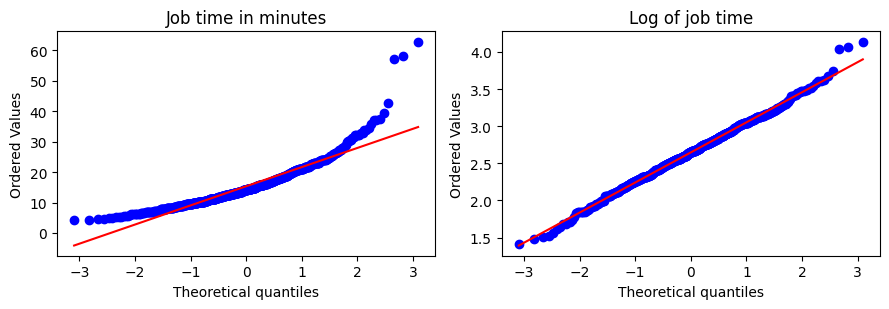

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
stats.probplot(lawn.minutes, dist="norm", plot=axes[0])
axes[0].set_title("Job time in minutes")
stats.probplot(np.log(lawn.minutes), dist="norm", plot=axes[1])
axes[1].set_title("Log of job time")
plt.tight_layout()
plt.show()

_Your answer:_  In the Q-Q plot for job time in minutes, the points bend noticeably upward at the ends, especially curling well above the reference line in the upper right tail, which reflects the strong right skew of the data. In the Q-Q plot for the log of job time, the points follow the straight reference line much more closely across the middle and both tails. Therefore, the log scale looks much closer to a normal distribution.



Part d. Calculate the mean and SD of `np.log(lawn.minutes)`. Use them as `mu_log`
and `sigma_log` in a lognormal model, then find its probability of a job taking more
than 30 minutes using `lognorm.sf(30, s=sigma_log, scale=np.exp(mu_log))`.
Compare this with part a and the observed proportion. Which model would you recommend
for estimating this probability, and what evidence supports your choice?

In [57]:
log_min = np.log(lawn.minutes)
mu_log = log_min.mean()
sigma_log = log_min.std()

p_over_30_lognorm = lognorm.sf(30, s=sigma_log, scale=np.exp(mu_log))

print(f"mu_log:             {mu_log:.4f}")
print(f"sigma_log:          {sigma_log:.4f}")
print(f"P(> 30) Lognormal:  {p_over_30_lognorm:.4f}")
print(f"P(> 30) Normal:     {p_over_30_norm:.4f}")
print(f"P(> 30) Observed:   {p_over_30_obs:.4f}")

mu_log:             2.6467
sigma_log:          0.4046
P(> 30) Lognormal:  0.0311
P(> 30) Normal:     0.0141
P(> 30) Observed:   0.0343


_Your answer:_ The lognormal model predicts a probability of 3.11%, of a job taking more than 30 minutes, which is much closer to the observed proportion of 3.43%, than the normal model's prediction of 1.41%. I would recommend the lognormal model for estimating this probability. This choice is supported by the Q-Q plot in part c showing that the log of job time follows a normal distribution much more closely than raw minutes, the fact that the lognormal model stays strictly positive instead of assigning probability to impossible negative job times, and its much closer match to the observed upper tail above 30 minutes.

